# Dry Bean Dataset

## Imports

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from ucimlrepo import fetch_ucirepo

## a) Load dataset

In [3]:
# load dry bean dataset from UCI ML repository
beans = fetch_ucirepo(id=602)
df = pd.concat([beans.data.features, beans.data.targets], axis=1)

# check for missing values
print("Missing values:\n", df.isna().sum())

# report the number of observations in each class
counts = df["Class"].value_counts()
print("\nClass counts:\n", counts)

# show the sizes and class proportions
props = df["Class"].value_counts(normalize=True)
print("\nClass proportions:\n", props)

Missing values:
 Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
Roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Class counts:
 Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Class proportions:
 Class
DERMASON    0.260525
SIRA        0.193667
SEKER       0.148924
HOROZ       0.141650
CALI        0.119756
BARBUNYA    0.097127
BOMBAY      0.038351
Name: proportion, dtype: float64


Stratification is useful because bean varieties naturally differ in size, shape, and other features. If we analyze the beans together, those group differences will make it more difficult to spot patterns. By splitting data into classes, we can compare similar groups, and whether relationships hold for each bean type separately.

## b) Unrestricted decision tree

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

X = df.drop(columns="Class")
y = df["Class"]
X_tr, X_val, y_tr, y_val = train_test_split(X, y, stratify=y, random_state=42)

tree = DecisionTreeClassifier(random_state=42, min_samples_leaf=1)
tree.fit(X_tr, y_tr)

y_tr_pred = tree.predict(X_tr)
y_val_pred = tree.predict(X_val)

print(f"depth={tree.get_depth()}, leaves={tree.get_n_leaves()}")
print(f"train_acc={accuracy_score(y_tr, y_tr_pred):.4f}")
print(f"val_acc={accuracy_score(y_val, y_val_pred):.4f}")
print(f"val_macro_f1={f1_score(y_val, y_val_pred, average='macro'):.4f}")

depth=27, leaves=637
train_acc=1.0000
val_acc=0.8924
val_macro_f1=0.9089


The model is fitting the training data perfectly, with a training accuracy of 1.00, but the validation accuracy is 0.8924 and the validation macro F1 is 0.9089. This shows slight overfitting, as the model memorizes the training set better than it generalizes to new data. Overall, the model is still performing well.

## c) Restricted decision trees

In [5]:
depths = [2, 4, 6, 8, 12, None]
rows = []

for d in depths:
    tree = DecisionTreeClassifier(random_state=42, max_depth=d)
    tree.fit(X_tr, y_tr)

    y_tr_pred = tree.predict(X_tr)
    y_val_pred = tree.predict(X_val)

    rows.append({
        "max_depth": d,
        "train_acc": accuracy_score(y_tr, y_tr_pred),
        "val_acc": accuracy_score(y_val, y_val_pred),
        "val_macro_f1": f1_score(y_val, y_val_pred, average="macro"),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

 max_depth  train_acc  val_acc  val_macro_f1
       2.0   0.656250 0.651190      0.451700
       4.0   0.828566 0.818689      0.754027
       6.0   0.914283 0.899500      0.908463
       8.0   0.940145 0.906553      0.919807
      12.0   0.983934 0.898031      0.913612
       NaN   1.000000 0.892448      0.908883


The results show tha deeper trees improve training accuracy, but validation performance peaks arounf depth 8 and then drops slightly at depth 12. Depth 8 provides the best validation accuracy and best validation macro-F1. At depth 12, the training accuracy increases even further, but validation accuracy and F1 decrease. Similarly for the unrestricted tree, training accuracy reaches 1.00, but validation accuracy and F1 decrease.

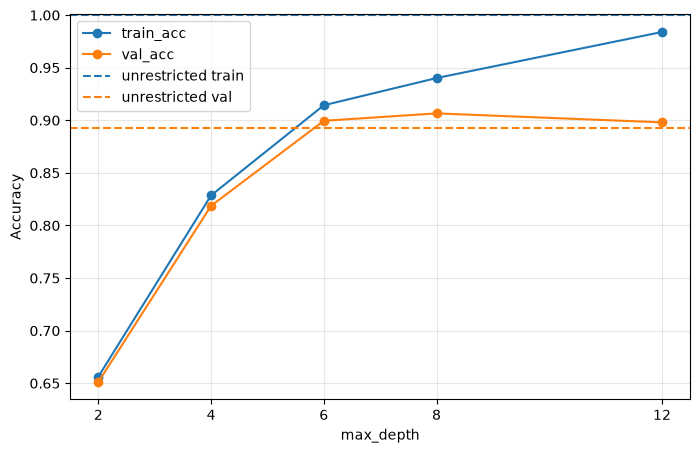

In [7]:
finite = results.dropna(subset=["max_depth"]).copy()
finite["max_depth"] = finite["max_depth"].astype(int)
unres = results[results["max_depth"].isna()].iloc[0]

plt.figure(figsize=(8, 5))
plt.plot(finite["max_depth"], finite["train_acc"], marker="o", label="train_acc")
plt.plot(finite["max_depth"], finite["val_acc"], marker="o", label="val_acc")
plt.axhline(unres["train_acc"], color="C0", linestyle="--", label="unrestricted train")
plt.axhline(unres["val_acc"], color="C1", linestyle="--", label="unrestricted val")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.xticks(finite["max_depth"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The plot shows that as `max_depth` increases, training accuracy keeps rising, but validation accuracy only improves until about depth 8. This indicates possible overfitting. The best balance is around `max_depth=8` where validation accuracy is highest. After that, the model does not generalize as well.

In [11]:
# select a depth using validation macro-F1, breaking ties in favor of simpler tree
candidate = results.copy()

# Make sure max_depth is stored as either an integer or None
candidate["max_depth"] = candidate["max_depth"].apply(
    lambda x: None if pd.isna(x) else int(x)
)

# Treat unrestricted tree as "infinite depth" so it loses ties to a smaller finite tree
candidate["depth_rank"] = candidate["max_depth"].apply(
    lambda x: float("inf") if x is None else x
)

best_row = candidate.sort_values(
    ["val_macro_f1", "depth_rank"],
    ascending=[False, True],
    kind="mergesort"
).iloc[0]

best_depth = None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"])

print(f"Selected max_depth: {best_depth}")
print(f"Best validation macro-F1: {best_row['val_macro_f1']:.4f}")

# fit the final tree using the chosen depth
best_tree = DecisionTreeClassifier(random_state=42, max_depth=best_depth)
best_tree.fit(X_tr, y_tr)

y_val_pred_best = best_tree.predict(X_val)
print(f"Final validation macro-F1: {f1_score(y_val, y_val_pred_best, average='macro'):.4f}")

Selected max_depth: 8
Best validation macro-F1: 0.9198
Final validation macro-F1: 0.9198
